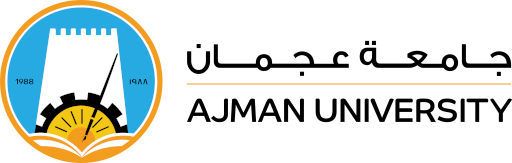

<table style="margin-left: 0; margin-right: auto;">
  <tr>
    <td><b>College:</b></td>
    <td>Engineering and Information Technology</td>
  </tr>
  <tr>
    <td><b>Department:</b></td>
    <td>Information Technology</td>
  </tr>
  <tr>
    <td><b>Program:</b></td>
    <td>Data Analytics and Artificial Intelligence</td>
  </tr>
  <tr>
    <td><b>Academic Semester:</b></td>
    <td>Spring 2025-2026</td>
  </tr>
  <tr>
    <td><b>Course:</b></td>
    <td>DAT405 Machine Learning Lab</td>
  </tr>
  <tr>
    <td><b>Course Instructor:</b></td>
    <td>Prof. Mahmoud AlShboul</td>
  </tr>
</table>


# **Lab 10: Transfer Learning and Fine-tuning**

## Introduction

Machine learning models typically require large amounts of data and computational resources to train from scratch. Pretrained models provide a way to leverage knowledge gained from training on large datasets, allowing you to fine-tune the model for your specific task with fewer resources.

In this section, we'll prepare our dataset using TensorFlow Datasets (TFDS), a collection of ready-to-use datasets for machine learning. We'll be working with the 'tf_flowers' dataset, which contains images of flowers across different categories.

## Helpful Links

- [TensorFlow Transfer Learning Tutorial](https://www.tensorflow.org/tutorials/images/transfer_learning)
- [Keras Pre-trained Models Documentation](https://keras.io/api/applications/)


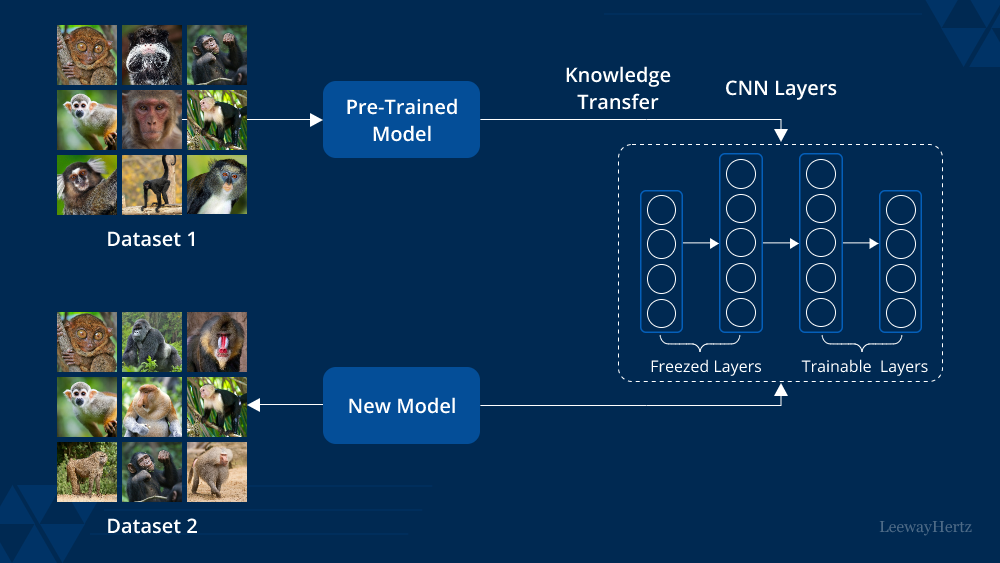

In [ ]:
# Import the TensorFlow Datasets (TFDS) library
# TFDS provides ready-to-use datasets for machine learning and deep learning, 
# easily integrated with TensorFlow.
import tensorflow_datasets as tfds


# Load the 'tf_flowers' dataset and split it into training, validation, and test sets.

(train_ds, val_ds, test_ds), ds_info = tfds.load(
    'tf_flowers',               # Name of the dataset (flowers dataset with 5 flower classes)
    split=[                     # Define custom dataset splits:
        'train[:80%]',          # First 80% of the data → training set
        'train[80%:90%]',       # Next 10% of the data → validation set
        'train[90%:]',          # Remaining 10% → test set
    ],
    as_supervised=True,         # Returns data as (image, label) pairs instead of dictionaries
    with_info=True              # Returns additional metadata about the dataset (like features, size, labels)
)

# Print detailed dataset information
# ds_info contains metadata such as:
#   - number of examples
#   - class labels
#   - image shape and type
#   - dataset citation and description
print(ds_info)


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/tf_flowers/incomplete.7XXSXX_3.0.1/tf_flowers-train.tfrecord*...:   0%|   …

Dataset tf_flowers downloaded and prepared to /root/tensorflow_datasets/tf_flowers/3.0.1. Subsequent calls will reuse this data.
tfds.core.DatasetInfo(
    name='tf_flowers',
    full_name='tf_flowers/3.0.1',
    description="""
    A large set of images of flowers
    """,
    homepage='https://www.tensorflow.org/tutorials/load_data/images',
    data_dir='/root/tensorflow_datasets/tf_flowers/3.0.1',
    file_format=tfrecord,
    download_size=218.21 MiB,
    dataset_size=221.83 MiB,
    features=FeaturesDict({
        'image': Image(shape=(None, None, 3), dtype=uint8),
        'label': ClassLabel(shape=(), dtype=int64, num_classes=5),
    }),
    supervised_keys=('image', 'label'),
    disable_shuffling=False,
    nondeterministic_order=False,
    splits={
        'train': <SplitInfo num_examples=3670, num_shards=2>,
    },
    citation="""@ONLINE {tfflowers,
    author = "The TensorFlow Team",
    title = "Flowers",
    month = "jan",
    year = "2019",
    url = "http://download.ten

Let's examine the structure of our data by looking at a few examples. This helps us understand the shape of our images and their corresponding labels.

In [2]:
for image, label in train_ds.take(3):
    print("Image shape:", image.shape)
    print("Label:", label.numpy())

Image shape: (333, 500, 3)
Label: 2
Image shape: (212, 320, 3)
Label: 3
Image shape: (240, 320, 3)
Label: 3


In [3]:
class_names = ds_info.features['label'].names
print("Class names:", class_names)

Class names: ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']


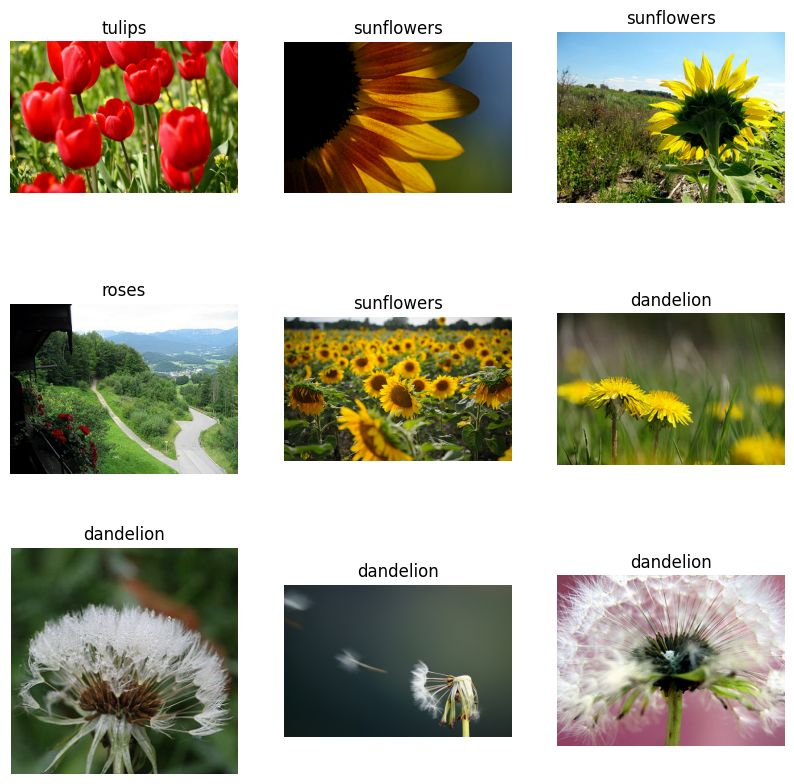

In [4]:
import matplotlib.pyplot as plt

# Function to display images and labels
def display_samples(dataset, class_names, num_samples=9):
    plt.figure(figsize=(10, 10))
    for i, (image, label) in enumerate(dataset.take(num_samples)):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(image)
        plt.title(class_names[label])
        plt.axis("off")
    plt.show()

# Display 9 images from the training dataset
display_samples(train_ds, class_names)


In [5]:
N_CLASSES = 5
IMAGE_SIZE = (260,260,3)
batch_size = 32

# Data Preprocessing and Augmentation

We prepare our images by resizing them to a standard size and rescaling their pixel values. For the training data, we've included optional augmentation techniques (currently commented out) that can help prevent overfitting. The datasets are then batched and optimized for performance using prefetching.

Note that every pretrained model has a specific requirement with regards to its image size and normalization.

In [ ]:
import tensorflow as tf

# ------------------------------
# Define preprocessing layers
# ------------------------------

# Create a resizing layer to ensure all input images have the same size.
resize = tf.keras.layers.Resizing(IMAGE_SIZE[0], IMAGE_SIZE[1])

# Create a rescaling layer to normalize pixel values.
# Original pixel values are in [0, 255].
# Multiplying by (1 / 127.5) and subtracting 1 scales them to [-1, 1],
# which is preferred by many pre-trained CNN models like MobileNet, Inception, etc.
rescale = tf.keras.layers.Rescaling(1/127.5, offset=-1)


# -----------------------------------------------------
# Define an augmentation function for training data
# -----------------------------------------------------
def train_augment(image, label):
    """
    This function is applied to each image-label pair in the training dataset.
    It performs preprocessing and (optionally) data augmentation.
    """

    # Resize each input image to the target size.
    image = resize(image)

    # The following commented-out augmentations can make the model more robust
    # by slightly modifying the training images each epoch.
    # Uncomment them to enable augmentations like rotation, flipping, and brightness.
    
    # Randomly rotate the image by 0, 90, 180, or 270 degrees.
    # image = tf.image.rot90(image, tf.random.uniform(shape=[], minval=0, maxval=4, dtype=tf.int32))
    
    # Randomly flip the image horizontally.
    # image = tf.image.random_flip_left_right(image)
    
    # Randomly flip the image vertically.
    # image = tf.image.random_flip_up_down(image)
    
    # Randomly adjust brightness for lighting variation.
    # image = tf.image.random_brightness(image, max_delta=0.4)

    # Rescale pixel values to the range [-1, 1]
    return rescale(image), label


# -----------------------------------------------------
# Define a preprocessing function for validation/test
# -----------------------------------------------------
def test_augment(image, label):
    """
    This function is used for validation and test datasets.
    It only resizes and rescales images without random augmentation.
    """
    image = resize(image)
    return rescale(image), label


# -----------------------------------------------------
# Apply preprocessing pipelines to all datasets
# -----------------------------------------------------

# The .map() method applies the augmentation function to each image-label pair.
# The .batch() method groups samples into batches for efficient training.
# The .prefetch() method overlaps preprocessing and model execution for better performance.

train_ds = train_ds.map(train_augment).batch(batch_size).prefetch(tf.data.AUTOTUNE)
val_ds   = val_ds.map(test_augment).batch(batch_size).prefetch(tf.data.AUTOTUNE)
test_ds  = test_ds.map(test_augment).batch(batch_size).prefetch(tf.data.AUTOTUNE)

# tf.data.AUTOTUNE → automatically tunes how much data is prefetched to optimize training speed.


In [7]:
print(len(train_ds))

92


In [8]:
# Function to calculate and print the size of the datasets
def print_dataset_sizes(train_ds, val_ds, test_ds):
    # Count the number of batches and samples in each dataset
    num_train_samples = sum(1 for _ in train_ds)
    num_val_samples = sum(1 for _ in val_ds)
    num_test_samples = sum(1 for _ in test_ds)

    print(f"Training dataset size: {num_train_samples} batches")
    print(f"Validation dataset size: {num_val_samples} batches")
    print(f"Test dataset size: {num_test_samples} batches")

# Call the function to print the sizes
print_dataset_sizes(train_ds, val_ds, test_ds)


Training dataset size: 92 batches
Validation dataset size: 12 batches
Test dataset size: 12 batches


# Building the Model with Transfer Learning

We create our model using EfficientNetV2B2, a pre-trained convolutional neural network. We remove its top layer and add our own custom classification layers to adapt it for flower classification. The model uses the weights from ImageNet training while being customized for our specific task.

In [9]:
from tensorflow.keras.applications import EfficientNetV2B2
from tensorflow.keras.layers import Input, Dense, GlobalAveragePooling2D
import tensorflow as tf

# Define input shape
input_shape = (260, 260, 3)
input_tensor = Input(shape=input_shape)

# Load the pre-trained EfficientNetV2B2 model
pre_trained_model = EfficientNetV2B2(include_top=False, weights='imagenet', input_tensor=input_tensor)

# Get the output of the last layer of the pre-trained model
last_output = pre_trained_model.output

# Add a custom dense layer on top of the pre-trained model
num_classes = 5  # Update this to match the number of classes in your dataset
x = GlobalAveragePooling2D()(last_output)  # Global average pooling layer to reduce the spatial dimensions
x = Dense(num_classes, activation='softmax')(x)  # Output layer for multi-class classification

# Create the new model
model = tf.keras.Model(inputs=pre_trained_model.input, outputs=x)

# Compile the model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Display model summary
model.summary()


35839040/35839040 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 260, 260,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 260, 260,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 260, 260,  │          0 │ rescaling_1[0][0] │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 130, 130,  │        864 │ normalization[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 130, 130,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 130, 130,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 130, 130,  │      4,608 │ stem_activation[… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_bn  │ (None, 130, 130,  │         64 │ block1a_project_… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_ac… │ (None, 130, 130,  │          0 │ block1a_project_… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1b_project_co… │ (None, 130, 130,  │      2,304 │ block1a_project_… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1b_project_bn  │ (None, 130, 130,  │         64 │ block1b_project_… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1b_project_ac… │ (None, 130, 130,  │          0 │ block1b_project_… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1b_drop        │ (None, 130, 130,  │          0 │ block1b_project_… │
│ (Dropout)           │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1b_add (Add)   │ (None, 130, 130,  │          0 │ block1b_drop[0][… │
│                     │ 16)               │            │ block1a_project_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_conv │ (None, 65, 65,    │      9,216 │ block1b_add[0][0] │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_bn   │ (None, 65, 65,    │        256 │ block2a_expand_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_act… │ (None, 65, 65,    │          0 │ block2a_expand_b

 Total params: 8,776,419 (33.48 MB)

 Trainable params: 8,694,131 (33.17 MB)

 Non-trainable params: 82,288 (321.44 KB)

# Setting Up Model Training Checkpoints

We configure callbacks to save the best performing model during training and implement early stopping to prevent overfitting. The model will be saved when validation accuracy improves, and training will stop if no improvement is seen for 25 epochs.

In [10]:
# Define the filepath for saving the best model
checkpoint_filepath = 'effnet_flowers_model.keras'

# Define the ModelCheckpoint callback
checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_filepath,
    monitor='val_accuracy',  # Monitor validation accuracy
    mode='max',              # Set to maximize validation accuracy
    save_best_only=True,     # Save only the best model according to the monitored metric
    save_weights_only=False, # Save the entire model, including architecture and weights
    verbose=1                # Display a message when saving the model
)

# Define the EarlyStopping callback
early_stopping_callback = tf.keras.callbacks.EarlyStopping(
    monitor='val_accuracy',  # Monitor validation accuracy
    patience=25,             # Stop training if accuracy doesn't improve for 25 epochs
    verbose=1,               # Display message when stopping
    mode='max'               # Stop when val_accuracy reaches a maximum and stops improving
)


# Training the Model

We train our model for up to 20 epochs using our prepared training and validation datasets. The training process will automatically save the best model and can stop early if the model's performance plateaus, thanks to our previously defined callbacks.

In [11]:
# Set up parameters for training
epochs = 20  # Maximum number of epochs; training may stop early due to EarlyStopping

# Train the model with the train and validation datasets
history = model.fit(
    train_ds,                      # Training dataset
    validation_data=val_ds,        # Validation dataset
    epochs=epochs,                 # Number of epochs
    callbacks=[checkpoint_callback, early_stopping_callback]  # Callbacks for saving and early stopping
)


Epoch 1/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 929ms/step - accuracy: 0.7298 - loss: 0.7164
Epoch 1: val_accuracy improved from -inf to 0.37875, saving model to effnet_flowers_model.keras
92/92 ━━━━━━━━━━━━━━━━━━━━ 226s 1s/step - accuracy: 0.7306 - loss: 0.7145 - val_accuracy: 0.3787 - val_loss: 1.5202
Epoch 2/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 238ms/step - accuracy: 0.9016 - loss: 0.2808
Epoch 2: val_accuracy did not improve from 0.37875
92/92 ━━━━━━━━━━━━━━━━━━━━ 23s 247ms/step - accuracy: 0.9017 - loss: 0.2806 - val_accuracy: 0.2970 - val_loss: 2.2197
Epoch 3/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 242ms/step - accuracy: 0.9425 - loss: 0.1886
Epoch 3: val_accuracy did not improve from 0.37875
92/92 ━━━━━━━━━━━━━━━━━━━━ 23s 250ms/step - accuracy: 0.9425 - loss: 0.1885 - val_accuracy: 0.3243 - val_loss: 1.4539
Epoch 4/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 236ms/step - accuracy: 0.9470 - loss: 0.1586
Epoch 4: val_accuracy improved from 0.37875 to 0.64578, saving model to effnet_flowers_model.keras
92/92 ━

In [12]:
best_model = tf.keras.models.load_model(checkpoint_filepath)

# Evaluate the best model on the test dataset
test_loss, test_accuracy = best_model.evaluate(test_ds)
print(f"Test Loss: {test_loss}")
print(f"Test Accuracy: {test_accuracy}")


12/12 ━━━━━━━━━━━━━━━━━━━━ 15s 414ms/step - accuracy: 0.9113 - loss: 0.3127
Test Loss: 0.2630181610584259
Test Accuracy: 0.9346048831939697


1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step


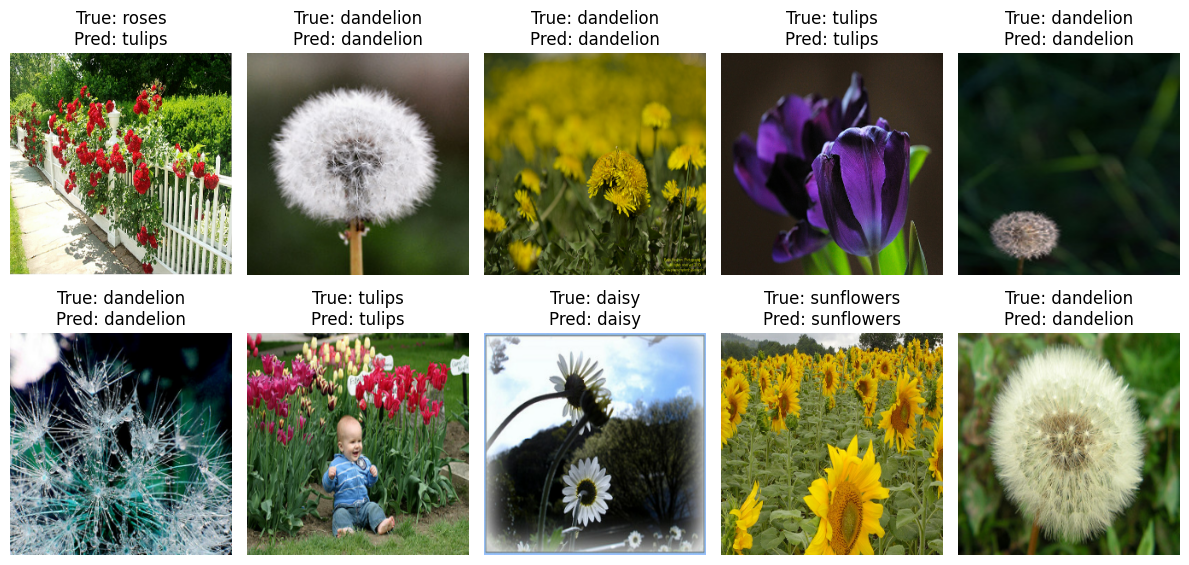

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Fetch a few samples from the test dataset to visualize
sample_batch = next(iter(test_ds))

# Extract images and labels from the batch
images, true_labels = sample_batch

# If images are scaled to [-1, 1], reverse the rescaling to [0, 255]
images_rescaled = (images + 1) * 127.5  # Reverse the rescaling formula

# Make predictions using the best model
predictions = best_model.predict(images)

# Convert predictions to class indices (highest probability)
predicted_labels = np.argmax(predictions, axis=-1)

# Display images along with their true and predicted labels
fig, axes = plt.subplots(2, 5, figsize=(12, 6))
axes = axes.flatten()

for i in range(10):
    ax = axes[i]
    ax.imshow(images_rescaled[i].numpy().astype("uint8"))  # Ensure image is in uint8 for proper display
    ax.set_title(f"True: {class_names[true_labels[i]]}\nPred: {class_names[predicted_labels[i]]}")
    ax.axis('off')

plt.tight_layout()
plt.show()


# **Lab Assignment**

Load and train any other pretrained model that we have not seen today on the TF_Flowers dataset. Experiment with different data augmentation methods and hyperparameters and report your results.

In [14]:
# Your code:
